In [ ]:
import kagglehub

path = kagglehub.dataset_download("ahemateja19bec1025/traffic-sign-dataset-classification")

print("Path to dataset files:", path)

100%|██████████| 190M/190M [00:05<00:00, 37.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ahemateja19bec1025/traffic-sign-dataset-classification/versions/2


In [ ]:
import os
import tensorflow as tf

base_data_dir = os.path.join(path, 'traffic_Data')

train_dir = os.path.join(base_data_dir, 'DATA')
test_dir = os.path.join(base_data_dir, 'TEST')

print(f"Training data directory: {train_dir}")
print(f"Test data directory: {test_dir}")

if not os.path.exists(train_dir):
    print(f"Warning: Training directory not found at {train_dir}")
if not os.path.exists(test_dir):
    print(f"Warning: Test directory not found at {test_dir}")

Training data directory: /root/.cache/kagglehub/datasets/ahemateja19bec1025/traffic-sign-dataset-classification/versions/2/traffic_Data/DATA
Test data directory: /root/.cache/kagglehub/datasets/ahemateja19bec1025/traffic-sign-dataset-classification/versions/2/traffic_Data/TEST


In [ ]:
tf.random.set_seed(42)

img_height = 128
img_width = 128

all_class_dirs_str = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))], key=int)

class_name_to_true_label_map = {name: int(name) for name in all_class_dirs_str}

global num_classes
num_classes = len(all_class_dirs_str)
print(f"Corrected number of classes: {num_classes}")

global class_names
class_names = all_class_dirs_str
print(f"Corrected class names: {class_names}")

# Collect train image paths and their true labels
train_image_paths_list = []
train_labels_list = []
for class_name_str in all_class_dirs_str:
    class_folder = os.path.join(train_dir, class_name_str)
    true_label = class_name_to_true_label_map[class_name_str]
    for fname in os.listdir(class_folder):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif')):
            train_image_paths_list.append(os.path.join(class_folder, fname))
            train_labels_list.append(true_label)

# Collect test image paths and their true labels
test_image_paths = sorted([
    os.path.join(test_dir, fname) for fname in os.listdir(test_dir)
    if fname.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))
])
test_labels_list = []
for img_path in test_image_paths:
    filename = os.path.basename(img_path)
    try:
        class_id_str = filename.split('_')[0]
        true_label = class_name_to_true_label_map[str(int(class_id_str))]
        test_labels_list.append(true_label)
    except (ValueError, IndexError, KeyError) as e:
        print(f"Could not infer or map class ID from filename: {filename}. Skipping. Error: {e}")

# Define a function to load and preprocess images
def preprocess_image(image_path, label):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [img_height, img_width])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

train_ds_raw = tf.data.Dataset.from_tensor_slices((train_image_paths_list, train_labels_list))
train_ds = train_ds_raw.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

test_ds_raw = tf.data.Dataset.from_tensor_slices((test_image_paths, test_labels_list))
test_ds = test_ds_raw.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE)

print(f"Number of elements in training set: {tf.data.experimental.cardinality(train_ds).numpy()}")
print(f"Number of elements in testing set: {tf.data.experimental.cardinality(test_ds).numpy()}")

Corrected number of classes: 58
Corrected class names: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57']
Number of elements in training set: 4170
Number of elements in testing set: 1994


### Visualize Sample Images
Let's visualize a few sample images from the training dataset to understand the data we are working with.

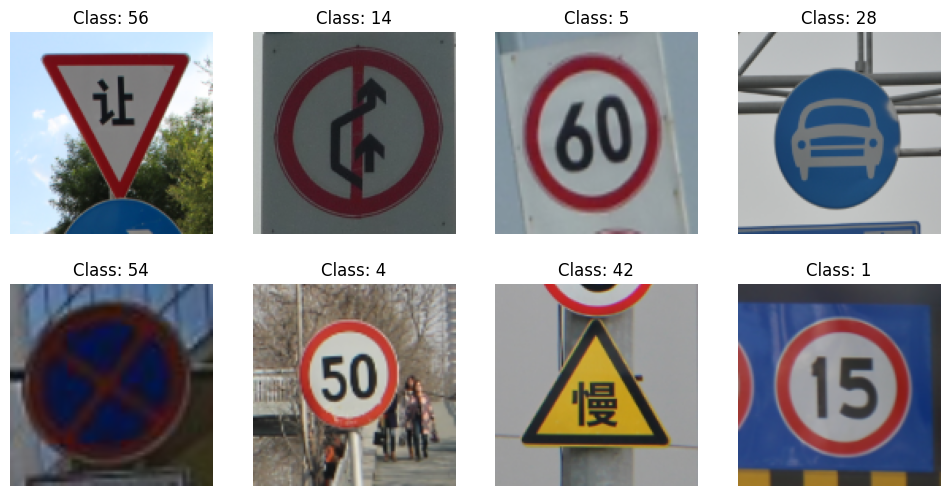

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
for i, (image, label) in enumerate(train_ds.shuffle(len(train_image_paths_list)).take(8)):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(image.numpy())
    plt.title(f"Class: {class_names[label.numpy()]}")
    plt.axis("off")
plt.show()

### 1. Prepare Traffic Sign Data for PyTorch
We convert the `tf.data.Dataset` objects (`train_ds` and `test_ds`) into PyTorch tensors and then create `DataLoader`s. Images will be transposed from `(height, width, channels)` to `(channels, height, width)` as expected by PyTorch's convolutional layers.

In [ ]:
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader

# Extract images and labels from train_ds
train_images = []
train_labels = []
for img, label in train_ds:
    train_images.append(img.numpy())
    train_labels.append(label.numpy())

train_images = np.array(train_images)
train_labels = np.array(train_labels)

# Extract images and labels from test_ds
test_images = []
test_labels_np = []
for img, label in test_ds:
    test_images.append(img.numpy())
    test_labels_np.append(label.numpy())

test_images = np.array(test_images)
test_labels_np = np.array(test_labels_np)

print(f"Shape of train_images: {train_images.shape}")
print(f"Shape of train_labels: {train_labels.shape}")
print(f"Shape of test_images: {test_images.shape}")
print(f"Shape of test_labels_np: {test_labels_np.shape}")

# Convert numpy arrays to torch tensors
train_images_torch = torch.from_numpy(train_images).permute(0, 3, 1, 2).float()
train_labels_torch = torch.from_numpy(train_labels).long()

test_images_torch = torch.from_numpy(test_images).permute(0, 3, 1, 2).float()
test_labels_torch = torch.from_numpy(test_labels_np).long()

# Create TensorDatasets
train_dataset = TensorDataset(train_images_torch, train_labels_torch)
test_dataset = TensorDataset(test_images_torch, test_labels_torch)

# Create DataLoaders
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"\nNumber of batches in train_loader: {len(train_loader)}")
print(f"Number of batches in test_loader: {len(test_loader)}")

Shape of train_images: (4170, 128, 128, 3)
Shape of train_labels: (4170,)
Shape of test_images: (1994, 128, 128, 3)
Shape of test_labels_np: (1994,)

Number of batches in train_loader: 131
Number of batches in test_loader: 63


### 2. Define the CNN Model using `torch.nn`
This model is a simple Convolutional Neural Network (CNN). It consists of three convolutional layers, followed by max-pooling layers (after the first two conv layers), and then fully connected layers for classification.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


# Define the CNN model
num_classes = len(class_names)

# class SimpleCNN(nn.Module):
#     def __init__(self, num_classes):
#         super().__init__()
#         self.features = nn.Sequential(
#             nn.Conv2d(3, 32, kernel_size=3, padding=1),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(2),  # 128x128 -> 64x64

#             nn.Conv2d(32, 64, kernel_size=3, padding=1),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(2),  # 64x64 -> 32x32

#             nn.Conv2d(64, 128, kernel_size=3, padding=1),
#             nn.ReLU(inplace=True),
#         )

#         # After features, tensor shape will be (Batch, 128, 32, 32)
#         # Flattened size: 128 * 32 * 32 = 131072
#         self.classifier = nn.Sequential(
#             nn.Flatten(),
#             nn.Linear(128 * 32 * 32, 256), # Adjusted for 128x128 input
#             nn.ReLU(inplace=True),
#             nn.Dropout(0.3),
#             nn.Linear(256, num_classes),
#         )

#     def forward(self, x):
#         x = self.features(x)
#         x = self.classifier(x)
#         return x



class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(in_channels=64, out_channels=64, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(64)
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(64 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        x = self.pool(F.relu(self.bn2(self.conv2(x))))
        x = F.relu(self.bn3(self.conv3(x)))

        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

model = SimpleCNN(num_classes)

### 3. Define Loss Function and Optimizer and Train the Model
We'll use `CrossEntropyLoss` for classification and the `Adam` optimizer to train the `SimpleCNN` model using the `train_loader` and evaluate its performance on the `test_loader`.

In [ ]:
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

print(f"Model will be trained on: {device}")

Model will be trained on: cuda


In [ ]:
num_epochs = 20

train_images_tensor = train_images_torch
train_labels_tensor = train_labels_torch

num_train_samples = len(train_images_tensor)
batch_size = BATCH_SIZE # 32

print(f"Starting training with Learning Rate: {optimizer.param_groups[0]['lr']}")

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    indices = torch.randperm(num_train_samples)

    for i in range(0, num_train_samples, batch_size):
        batch_indices = indices[i:i + batch_size]
        inputs = train_images_tensor[batch_indices].to(device)
        labels = train_labels_tensor[batch_indices].to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_accuracy = 100 * correct_train / total_train
    avg_train_loss = running_loss / (num_train_samples / batch_size) if (num_train_samples / batch_size) > 0 else 0
    print(f'Epoch {epoch + 1}, Loss: {avg_train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')

    # Evaluate on the test set
    model.eval()
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()

    test_accuracy = 100 * correct_test / total_test
    print(f'Test Accuracy after Epoch {epoch + 1}: {test_accuracy:.2f}%')

print('\nFinished Training')

Starting training with Learning Rate: 0.0001
Epoch 1, Loss: 2.2769, Train Accuracy: 45.71%
Test Accuracy after Epoch 1: 37.91%
Epoch 2, Loss: 0.9696, Train Accuracy: 75.78%
Test Accuracy after Epoch 2: 47.14%
Epoch 3, Loss: 0.5408, Train Accuracy: 86.83%
Test Accuracy after Epoch 3: 50.15%
Epoch 4, Loss: 0.3469, Train Accuracy: 92.04%
Test Accuracy after Epoch 4: 51.86%
Epoch 5, Loss: 0.2329, Train Accuracy: 94.32%
Test Accuracy after Epoch 5: 53.86%
Epoch 6, Loss: 0.1804, Train Accuracy: 95.78%
Test Accuracy after Epoch 6: 55.67%
Epoch 7, Loss: 0.1362, Train Accuracy: 96.88%
Test Accuracy after Epoch 7: 53.56%
Epoch 8, Loss: 0.1024, Train Accuracy: 97.96%
Test Accuracy after Epoch 8: 55.17%
Epoch 9, Loss: 0.0826, Train Accuracy: 98.37%
Test Accuracy after Epoch 9: 57.07%
Epoch 10, Loss: 0.0806, Train Accuracy: 98.32%
Test Accuracy after Epoch 10: 57.37%
Epoch 11, Loss: 0.0724, Train Accuracy: 98.63%
Test Accuracy after Epoch 11: 58.38%
Epoch 12, Loss: 0.0706, Train Accuracy: 98.30%
Te

### 4. Examine a Test Sample
We examine a sample from the test set and run inference from our model on the image.

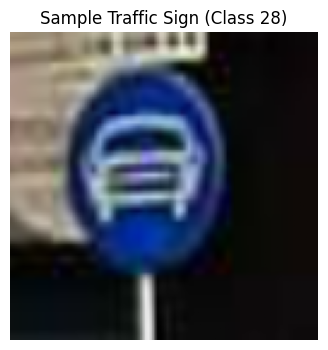

In [ ]:
sample_idx = 1111
sample_traffic_sign = test_images_torch[sample_idx].unsqueeze(0).to(device)

img_to_show = sample_traffic_sign.squeeze(0).cpu().numpy()
img_to_show = img_to_show.transpose(1, 2, 0)

plt.figure(figsize=(4, 4))
plt.imshow(img_to_show)
plt.title(f"Sample Traffic Sign (Class {test_labels_torch[sample_idx].item()})")
plt.axis('off')
plt.show()

In [ ]:
model.eval()
with torch.no_grad():
    outputs = model(sample_traffic_sign)
    probs = torch.softmax(outputs, dim=1)

    # Get the predicted class and its confidence
    # Depending on the RNG used in training the model, this iteration of the model may or may not even guess the correct class in the first training attempt
    pred_class_idx = probs.argmax(dim=1).item()
    confidence = probs[0, pred_class_idx].item()

print(f"Predicted Class: {class_names[pred_class_idx]}")
print(f"Confidence: {confidence:.4f}")

Predicted Class: 4
Confidence: 0.7168


### 5. Define Fast Gradient Sign Method
We'll use `fgsm_attack` to create adversarial attacks and test on our `SimpleCNN`.

In [ ]:
def fgsm_attack(model, x, y, epsilon=0.05):
    """
    x is normalized input (expected in [0, 1] range for this model).
    Returns:
        x_adv: adversarial example in normalized space
        grad: gradient wrt input
    """
    model.eval()

    x_adv = x.clone().detach().requires_grad_(True)
    logits = model(x_adv)
    loss = criterion(logits, y)

    model.zero_grad()
    loss.backward()

    grad = x_adv.grad.detach()
    x_adv = x_adv + epsilon * grad.sign()

    x_adv = torch.clamp(x_adv, 0, 1)

    return x_adv.detach(), grad

In [ ]:
# Get the true label for the sample
true_label_for_sample = test_labels_torch[sample_idx].unsqueeze(0).to(device)

# Create the adversarial traffic sign
epsilon = 0.03
adversarial_traffic_sign, grad0 = fgsm_attack(model, sample_traffic_sign, true_label_for_sample, epsilon=epsilon)

In [ ]:
model.eval()
with torch.no_grad():
    outputs_adv = model(adversarial_traffic_sign)
    probs_adv = torch.softmax(outputs_adv, dim=1)

    # Get the predicted class and its confidence for the adversarial example
    pred_adv_class_idx = probs_adv.argmax(dim=1).item()
    confidence_adv = probs_adv[0, pred_adv_class_idx].item()

print(f"Adversarial Predicted Class: {class_names[pred_adv_class_idx]}")
print(f"Adversarial Confidence: {confidence_adv:.4f}")

Adversarial Predicted Class: 4
Adversarial Confidence: 0.9876


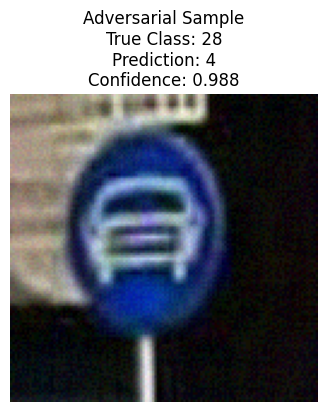

In [ ]:
img_to_show_adv = adversarial_traffic_sign.squeeze(0).cpu().numpy()
img_to_show_adv = img_to_show_adv.transpose(1, 2, 0)

plt.figure(figsize=(4, 4))
plt.imshow(img_to_show_adv)
plt.title(f"Adversarial Sample\nTrue Class: {class_names[true_label_for_sample.item()]}\nPrediction: {class_names[pred_adv_class_idx]}\nConfidence: {confidence_adv:.3f}")
plt.axis('off')
plt.show()

In [ ]:
# Heat Map (redacted)

# grad0_np = grad0.squeeze(0).cpu().numpy()
# grad0_np = np.transpose(grad0_np, (1, 2, 0))

# plt.figure(figsize=(4, 4))
# max_grad_val = np.max(np.abs(grad0_np[:, :, 0]))
# plt.imshow(grad0_np[:, :, 0], cmap='RdBu', vmin=-max_grad_val, vmax=max_grad_val)
# plt.colorbar(label='Signed Gradient Magnitude')
# plt.title("Signed Gradient Heatmap")
# plt.axis('off')
# plt.show()

### 6. Test our CNN model on adversarial attacks with the Fast Gradient Sign Method
Run inference on our CNN model to examine its accuracy on the original test images in `test_loader` and the `adversarial_images` created from `fgsm_attack`.

In [ ]:
correct_original_predictions = 0
total_original_predictions = 0
correct_adversarial_predictions = 0
total_adversarial_predictions = 0

model.eval()
epsilon = 0.05

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    # Calculate original model accuracy
    with torch.no_grad():
        outputs_original = model(images)
        _, predicted_original = torch.max(outputs_original.data, 1)

    total_original_predictions += labels.size(0)
    correct_original_predictions += (predicted_original == labels).sum().item()

    # Create adversarial examples for the batch
    adversarial_images, _ = fgsm_attack(model, images, labels, epsilon=epsilon)

    # Perform inference on the adversarial images.
    with torch.no_grad():
        outputs_adv = model(adversarial_images)
        _, predicted_adv = torch.max(outputs_adv.data, 1)

    total_adversarial_predictions += labels.size(0)
    correct_adversarial_predictions += (predicted_adv == labels).sum().item()

original_accuracy = 100 * correct_original_predictions / total_original_predictions
adversarial_accuracy = 100 * correct_adversarial_predictions / total_adversarial_predictions

print(f'Original Accuracy on Test Set: {original_accuracy:.2f}%')
print(f'Adversarial Accuracy on Test Set: {adversarial_accuracy:.2f}%')

Original Accuracy on Test Set: 59.28%
Adversarial Accuracy on Test Set: 16.85%


### 7. Post-Training Fine-Tuning of our original model
We create a new model `model_adv_finetuned` that contains the same parameters as our original `model`, and fine-tune the parameters through post-training. Test `model_adv_finetuned` on the original test images as well as the adversarial images.

In [ ]:
training_epsilon = 0.05

# Initialize a new model instance for retraining
model_adv_finetuned = SimpleCNN(num_classes).to(device)

# Load the state dictionary from the original trained model into this new instance
# This effectively 'post-trains' the original model's weights
model_adv_finetuned.load_state_dict(model.state_dict())

optimizer_adv = optim.Adam(model_adv_finetuned.parameters(), lr=0.0001)

print("\nStarting post-training adversarial examples...")

num_epochs_adv = 10 # Using the half the number of epochs as original training

for epoch in range(num_epochs_adv):
    model_adv_finetuned.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader: # Use original train_loader
        images, labels = images.to(device), labels.to(device)
        images.requires_grad = True
        outputs_for_grad = model_adv_finetuned(images)
        loss_for_grad = criterion(outputs_for_grad, labels)

        model_adv_finetuned.zero_grad()
        loss_for_grad.backward(retain_graph=True)

        # Generate adversarial examples from the input gradients
        if images.grad is not None:
            adv_images = images + training_epsilon * images.grad.sign()
            adv_images = torch.clamp(adv_images, 0, 1)
        else:
            adv_images = images.detach()

        # Forward pass for clean and adversarial images to compute combined loss
        outputs_clean_for_combined = model_adv_finetuned(images) # Evaluate clean image
        outputs_adv_for_combined = model_adv_finetuned(adv_images) # Evaluate adversarial image

        # Combined loss, taking into account loss for original images and loss for adversarial images
        loss = (criterion(outputs_clean_for_combined, labels) + criterion(outputs_adv_for_combined, labels)) / 2

        # Optimize model parameters based on the combined loss
        optimizer_adv.zero_grad()
        loss.backward()
        optimizer_adv.step()
        running_loss += loss.item()

        _, predicted = torch.max(outputs_clean_for_combined.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_accuracy = 100 * correct_train / total_train
    avg_train_loss = running_loss / len(train_loader) if len(train_loader) > 0 else 0 # Use train_loader here
    print(f'Epoch {epoch + 1}, Loss: {avg_train_loss:.4f}, On-the-fly Adv Train Accuracy: {train_accuracy:.2f}%')

    # Evaluate on the original test set
    model_adv_finetuned.eval()
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            images_test, labels_test = data[0].to(device), data[1].to(device)
            outputs_test = model_adv_finetuned(images_test)
            _, predicted_test = torch.max(outputs_test.data, 1)
            total_test += labels_test.size(0)
            correct_test += (predicted_test == labels_test).sum().item()

    test_accuracy = 100 * correct_test / total_test
    print(f'Test Accuracy (on original test set) after Epoch {epoch + 1}: {test_accuracy:.2f}%')

print('\nFinished Post-Training Adversarial Training')


Starting post-training adversarial examples...
Epoch 1, Loss: 0.2739, On-the-fly Adv Train Accuracy: 98.92%
Test Accuracy (on original test set) after Epoch 1: 60.28%
Epoch 2, Loss: 0.1976, On-the-fly Adv Train Accuracy: 98.87%
Test Accuracy (on original test set) after Epoch 2: 59.48%
Epoch 3, Loss: 0.1571, On-the-fly Adv Train Accuracy: 99.04%
Test Accuracy (on original test set) after Epoch 3: 60.88%
Epoch 4, Loss: 0.1471, On-the-fly Adv Train Accuracy: 99.14%
Test Accuracy (on original test set) after Epoch 4: 62.69%
Epoch 5, Loss: 0.1177, On-the-fly Adv Train Accuracy: 99.42%
Test Accuracy (on original test set) after Epoch 5: 59.88%
Epoch 6, Loss: 0.1179, On-the-fly Adv Train Accuracy: 99.14%
Test Accuracy (on original test set) after Epoch 6: 60.88%
Epoch 7, Loss: 0.1139, On-the-fly Adv Train Accuracy: 99.09%
Test Accuracy (on original test set) after Epoch 7: 61.08%
Epoch 8, Loss: 0.0967, On-the-fly Adv Train Accuracy: 99.11%
Test Accuracy (on original test set) after Epoch 8:

In [ ]:
correct_original_adv_trained_predictions = 0
total_original_adv_trained_predictions = 0
correct_adversarial_adv_trained_predictions = 0
total_adversarial_adv_trained_predictions = 0

model_adv_finetuned.eval()
epsilon = 0.05 # Using the same epsilon

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    # Evaluate on original test images
    with torch.no_grad():
        outputs_original_adv_trained = model_adv_finetuned(images)
        _, predicted_original_adv_trained = torch.max(outputs_original_adv_trained.data, 1)

    total_original_adv_trained_predictions += labels.size(0)
    correct_original_adv_trained_predictions += (predicted_original_adv_trained == labels).sum().item()

    # Generate adversarial images for evaluation using the originally trained model
    adv_images_for_eval, _ = fgsm_attack(model, images, labels, epsilon=epsilon)

    # Evaluate on adversarial test images
    with torch.no_grad():
        outputs_adv_adv_trained = model_adv_finetuned(adv_images_for_eval)
        _, predicted_adv_adv_trained = torch.max(outputs_adv_adv_trained.data, 1)

    total_adversarial_adv_trained_predictions += labels.size(0)
    correct_adversarial_adv_trained_predictions += (predicted_adv_adv_trained == labels).sum().item()

original_accuracy_adv_finetuned = 100 * correct_original_adv_trained_predictions / total_original_adv_trained_predictions
adversarial_accuracy_adv_finetuned = 100 * correct_adversarial_adv_trained_predictions / total_adversarial_adv_trained_predictions

print(f'Model trained with adversarial examples (Adversarially Trained Model):')
print(f'  Accuracy on Original Test Set: {original_accuracy_adv_finetuned:.2f}%')
print(f'  Accuracy on Adversarial Test Set: {adversarial_accuracy_adv_finetuned:.2f}%')

Model trained with adversarial examples (Adversarially Trained Model):
  Accuracy on Original Test Set: 63.79%
  Accuracy on Adversarial Test Set: 35.71%


### 8. Augmenting Training Data and Retraining a new Model

We will now train a fresh instance of our `SimpleCNN` model on adversarial images and the original images. Then, run inference with `model_adv_trained` on the original test images and the adversarial test images.

In [ ]:
training_epsilon = 0.05

# Initialize a new model for retraining
model_adv_trained = SimpleCNN(num_classes).to(device)
optimizer_adv = optim.Adam(model_adv_trained.parameters(), lr=0.0001)

print("\nStarting training with augemented adversarial examples...")

num_epochs_adv = 20 # Using the same number of epochs as original training

for epoch in range(num_epochs_adv):
    model_adv_trained.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        images.requires_grad = True

        outputs_for_grad = model_adv_trained(images)
        loss_for_grad = criterion(outputs_for_grad, labels)

        model_adv_trained.zero_grad()
        loss_for_grad.backward(retain_graph=True)

        # Generate adversarial examples from the input gradients
        if images.grad is not None:
            adv_images = images + training_epsilon * images.grad.sign()
            adv_images = torch.clamp(adv_images, 0, 1)
        else:
            adv_images = images.detach()

        # Forward pass for clean and adversarial images to compute combined loss
        outputs_clean_for_combined = model_adv_trained(images)
        outputs_adv_for_combined = model_adv_trained(adv_images)

        # Combined loss
        loss = (criterion(outputs_clean_for_combined, labels) + criterion(outputs_adv_for_combined, labels)) / 2

        optimizer_adv.zero_grad()
        loss.backward()
        optimizer_adv.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs_clean_for_combined.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    train_accuracy = 100 * correct_train / total_train
    avg_train_loss = running_loss / len(train_loader) if len(train_loader) > 0 else 0 # Use train_loader here
    print(f'Epoch {epoch + 1}, Loss: {avg_train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%')

    # Evaluate on the original test set
    model_adv_trained.eval()
    correct_test = 0
    total_test = 0
    with torch.no_grad():
        for data in test_loader:
            images_test, labels_test = data[0].to(device), data[1].to(device)
            outputs_test = model_adv_trained(images_test)
            _, predicted_test = torch.max(outputs_test.data, 1)
            total_test += labels_test.size(0)
            correct_test += (predicted_test == labels_test).sum().item()

    test_accuracy = 100 * correct_test / total_test
    print(f'Test Accuracy (on original test set) after Epoch {epoch + 1}: {test_accuracy:.2f}%')

print('\nFinished Augmented Adversarial Training')


Starting training with augemented adversarial examples...
Epoch 1, Loss: 2.8945, Train Accuracy: 37.03%
Test Accuracy (on original test set) after Epoch 1: 37.11%
Epoch 2, Loss: 1.7122, Train Accuracy: 64.87%
Test Accuracy (on original test set) after Epoch 2: 42.03%
Epoch 3, Loss: 1.1574, Train Accuracy: 77.36%
Test Accuracy (on original test set) after Epoch 3: 47.74%
Epoch 4, Loss: 0.8715, Train Accuracy: 83.55%
Test Accuracy (on original test set) after Epoch 4: 51.25%
Epoch 5, Loss: 0.6968, Train Accuracy: 88.37%
Test Accuracy (on original test set) after Epoch 5: 55.07%
Epoch 6, Loss: 0.5927, Train Accuracy: 89.71%
Test Accuracy (on original test set) after Epoch 6: 56.57%
Epoch 7, Loss: 0.4915, Train Accuracy: 91.65%
Test Accuracy (on original test set) after Epoch 7: 59.78%
Epoch 8, Loss: 0.4220, Train Accuracy: 93.12%
Test Accuracy (on original test set) after Epoch 8: 60.38%
Epoch 9, Loss: 0.3853, Train Accuracy: 94.27%
Test Accuracy (on original test set) after Epoch 9: 59.

### Evaluate Adversarially Trained Model on Original and Adversarial Test Sets

Now we will evaluate the new `model_adv_trained` on both the original test set and a generated adversarial test set. This will show if adversarial training improved robustness without significantly degrading original performance.

In [ ]:
correct_original_adv_trained_predictions = 0
total_original_adv_trained_predictions = 0
correct_adversarial_adv_trained_predictions = 0
total_adversarial_adv_trained_predictions = 0

model_adv_trained.eval()
epsilon = 0.05 # Using the same epsilon

for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)

    # Evaluate on original test images
    with torch.no_grad():
        outputs_original_adv_trained = model_adv_trained(images)
        _, predicted_original_adv_trained = torch.max(outputs_original_adv_trained.data, 1)

    total_original_adv_trained_predictions += labels.size(0)
    correct_original_adv_trained_predictions += (predicted_original_adv_trained == labels).sum().item()
    adv_images_for_eval, _ = fgsm_attack(model, images, labels, epsilon=epsilon)

    # Evaluate on adversarial test images
    with torch.no_grad():
        outputs_adv_adv_trained = model_adv_trained(adv_images_for_eval)
        _, predicted_adv_adv_trained = torch.max(outputs_adv_adv_trained.data, 1)

    total_adversarial_adv_trained_predictions += labels.size(0)
    correct_adversarial_adv_trained_predictions += (predicted_adv_adv_trained == labels).sum().item()

original_accuracy_adv_trained = 100 * correct_original_adv_trained_predictions / total_original_adv_trained_predictions
adversarial_accuracy_adv_trained = 100 * correct_adversarial_adv_trained_predictions / total_adversarial_adv_trained_predictions

print(f'Model trained with adversarial examples (Adversarially Trained Model):')
print(f'  Accuracy on Original Test Set: {original_accuracy_adv_trained:.2f}%')
print(f'  Accuracy on Adversarial Test Set: {adversarial_accuracy_adv_trained:.2f}%')

Model trained with adversarial examples (Adversarially Trained Model):
  Accuracy on Original Test Set: 63.99%
  Accuracy on Adversarial Test Set: 56.07%


### 9. Plot the accuracies of all three models
Visual representation of test set accuracy and the adversarial test set accuracy on the three models: original model, original model with post training fine-tuning, and a newly trained model on the original training set and the adversarial training set

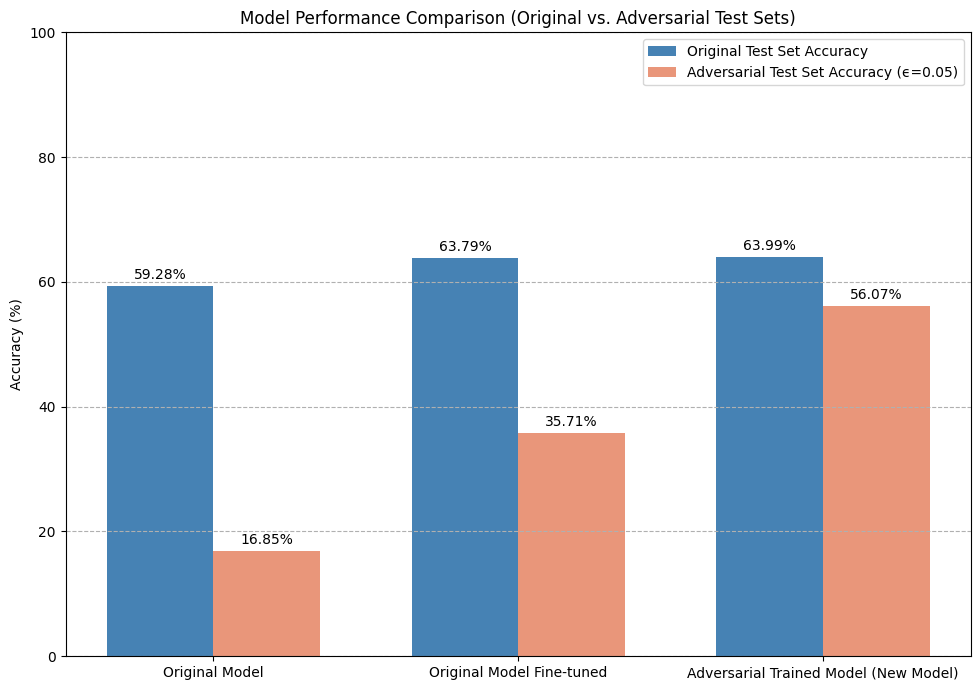

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Data for plotting
models = ['Original Model', 'Original Model Fine-tuned', 'Adversarial Trained Model (New Model)']
original_test_accuracies = [original_accuracy, original_accuracy_adv_finetuned, original_accuracy_adv_trained]
adversarial_test_accuracies = [adversarial_accuracy, adversarial_accuracy_adv_finetuned, adversarial_accuracy_adv_trained]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 7))
rects1 = ax.bar(x - width/2, original_test_accuracies, width, label='Original Test Set Accuracy', color='steelblue')
rects2 = ax.bar(x + width/2, adversarial_test_accuracies, width, label=f'Adversarial Test Set Accuracy (ϵ={epsilon})', color='darksalmon')

ax.set_ylabel('Accuracy (%)')
ax.set_title('Model Performance Comparison (Original vs. Adversarial Test Sets)')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.set_ylim(0, 100)

def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
ax.grid(axis='y', linestyle='--')
plt.show()